# Đánh giá dữ liệu Parquet đã xử lý

Notebook này phân tích đệ quy toàn bộ file Parquet trong `data/processed` và kiểm tra giao thức chia dữ liệu E4 trong `data/processed/e4`.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
if not (root / "src").exists():
    raise RuntimeError("Không tìm thấy thư mục gốc repository")

sys.path.insert(0, str(root))
print("Repository:", root)

Repository: d:\msis406\amazon-electronics-bigdata-recommender


In [2]:
import json
import pandas as pd

from src.evaluation.analyze_processed_data import (
    markdown_report,
    profile_tree,
    validate_e4,
    write_summary_csv,
)

In [3]:
data_root = root / "data" / "processed"
e4_dir = data_root / "e4"
out_dir = root / "outputs" / "reports" / "Electronics" / "parquet_assessment"

processed = profile_tree(data_root)
e4 = validate_e4(e4_dir) if e4_dir.is_dir() else None

out_dir.mkdir(parents=True, exist_ok=True)
write_summary_csv(processed, out_dir)
(out_dir / "parquet_dataset_profile.json").write_text(
    json.dumps({"datasets": processed}, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
(out_dir / "parquet_assessment.md").write_text(markdown_report(processed, e4), encoding="utf-8")

if e4:
    (out_dir / "e4_integrity.json").write_text(
        json.dumps(e4, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
    )

## 1. Tổng quan thư mục dữ liệu đã xử lý

In [4]:
summary = pd.DataFrame([{
    "dataset": item["dataset"],
    "file_count": item["file_count"],
    "rows": item["rows"],
    "size": item["human_size"],
    "key_columns": " | ".join(item["key_columns"]),
    "duplicate_key_rows": item["key_duplicate_rows"],
} for item in processed])
summary

,dataset,file_count,rows,size,key_columns,duplicate_key_rows
0,e4,3,1031437,21.6 MB,user_id | product_id,0
1,e4/audit/test,2,650241,10.6 MB,,0
2,e4/audit/validation,2,591607,9.7 MB,,0
3,metadata_clean,2,378040,35.2 MB,asin,0
4,ratings_clean,4,10276744,243.0 MB,user_id | product_id,0
5,ratings_enriched,5,10207559,997.9 MB,user_id | product_id,0


## 2. Kiểm tra tính toàn vẹn E4

In [5]:
if e4 is None:
    raise FileNotFoundError(e4_dir)

checks = pd.DataFrame(e4["checks"])
checks["result"] = checks["passed"].map({True: "PASS", False: "FAIL"})
checks[["name", "result", "detail"]]

,name,result,detail
0,split_files_present,PASS,"train.parquet, validation.parquet and test.par..."
1,pair_unique_in_each_split,PASS,No repeated user-item pair inside each split
2,pair_unique_across_splits,PASS,No user-item pair appears in more than one split
3,temporal_boundaries,PASS,Train < 2017-02-01 <= Validation < 2017-10-01 ...
4,ratings_in_valid_range,PASS,Every rating is an integer-valued number from ...
5,cold_start_cohort_totals,PASS,Four cold-start cohorts reconcile to each held...


,split,pairs,users,items,relevant_pairs,min_timestamp,max_timestamp
0,train,819984,401457,190150,623757,931824000,1485820800
1,validation,106147,73221,41892,80126,1485907200,1506729600
2,test,105306,75009,36447,77935,1506816000,1538524800


Text(0, 0.5, 'Pairs')

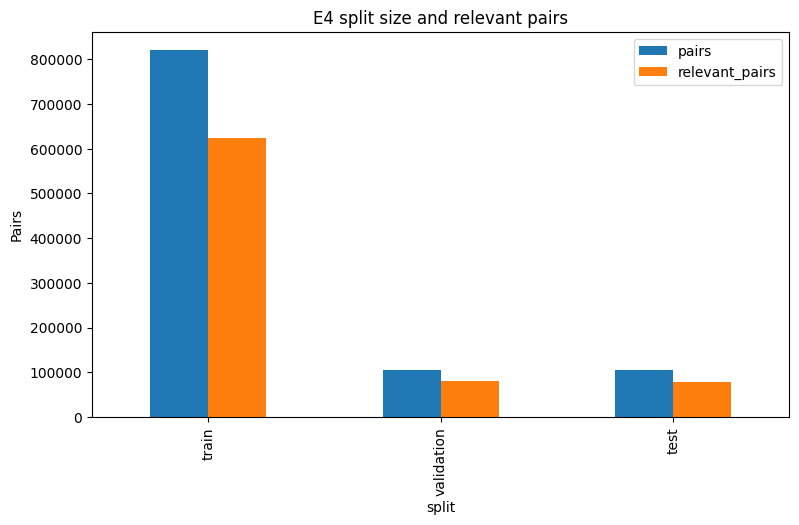

In [6]:
split_stats = pd.DataFrame(e4["split_statistics"])
display(split_stats)

ax = split_stats.set_index("split")[["pairs", "relevant_pairs"]].plot(
    kind="bar", figsize=(9, 5), title="E4 split size and relevant pairs"
)
ax.set_ylabel("Pairs")

## 3. Phân phối đánh giá và cold-start

<Axes: title={'center': 'Rating distribution by E4 split'}, xlabel='rating'>

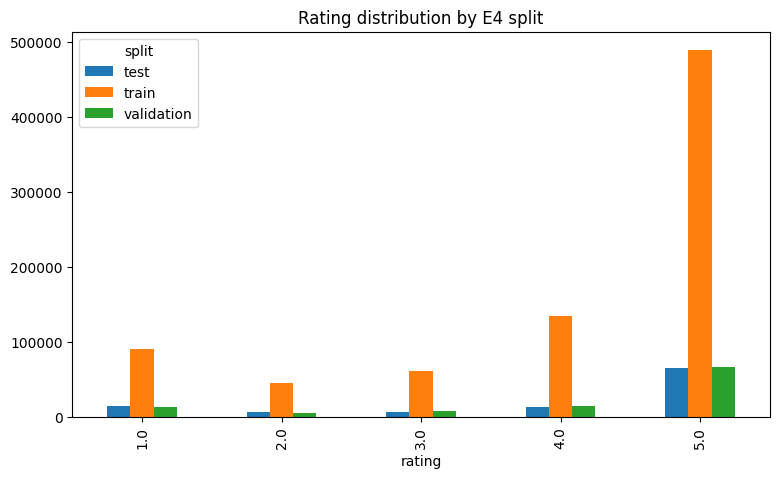

In [7]:
frames = {
    name: pd.read_parquet(e4_dir / f"{name}.parquet")
    for name in ("train", "validation", "test")
}

rating_plot = pd.concat(
    [frame.assign(split=name)[["split", "rating"]] for name, frame in frames.items()],
    ignore_index=True,
)
rating_plot.groupby(["split", "rating"]).size().unstack(0).plot(
    kind="bar", figsize=(9, 5), title="Rating distribution by E4 split"
)

,phase,group,pairs,users,items,relevant_pairs,total_held_out_pairs,unknown_user_pairs,unknown_item_pairs,pair_share_of_held_out
0,validation,all,106147,73221,41892,80126,106147,57756,17998,1.000000
1,validation,warm_user/warm_item,39946,24592,17970,31215,106147,0,0,0.376327
2,validation,cold_user/warm_item,48203,38299,19540,35414,106147,48203,0,0.454116
3,validation,warm_user/cold_item,8445,6981,7142,6639,106147,0,8445,0.079559
4,validation,cold_user/cold_item,9553,8865,7715,6858,106147,9553,9553,0.089998
5,validation,history_0,57756,44934,27255,42272,106147,57756,9553,0.544113
6,validation,history_1-4,31060,20801,18103,23890,106147,0,5336,0.292613
7,validation,history_5+,17331,7486,11646,13964,106147,0,3109,0.163274
8,test,all,105306,75009,36447,77935,105306,57923,15372,1.000000
9,test,warm_user/warm_item,40458,25809,16768,31040,105306,0,0,0.384195


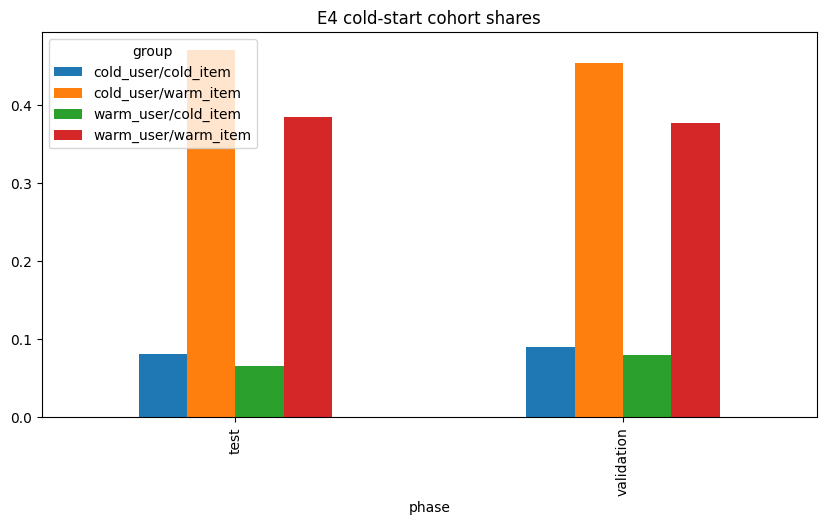

In [8]:
cold_start_path = e4_dir / "audit" / "cold_start.csv"
if cold_start_path.is_file():
    cold = pd.read_csv(cold_start_path)
    display(cold)

    cohort = cold[cold["group"].str.contains("user/", regex=False)]
    cohort.pivot(index="phase", columns="group", values="pair_share_of_held_out").plot(
        kind="bar", figsize=(10, 5), title="E4 cold-start cohort shares"
    )
else:
    print("Chưa có audit/cold_start.csv; chạy audit E4 trước.")